- TSP https://www.youtube.com/watch?v=GiDsjIBOVoA
- get API key from https://collegefootballdata.com/key
- %pip install highspy
- "tools" API, algorithm, hueristic, runtime complexity, map, tour

In [1]:
import os
import requests
import pandas as pd

# Set your API key if not already in your environment
os.environ["CFBD_API_KEY"] = "k2AF0ZrIjAMEN+dJzflnaEzMFZuuZqkCe7CQN9F+C0lcbPTyC/48vg4LTZmElD6a"

headers = {"Authorization": f"Bearer {os.environ['CFBD_API_KEY']}"}

resp = requests.get(
    "https://api.collegefootballdata.com/teams/fbs",
    headers=headers,
    params={"year": 2026}
)
resp.raise_for_status()

df = pd.json_normalize(resp.json())

cols = {
    "school": "team",
    "conference": "conference",
    "color": "color",
    "location.name": "stadium",
    "location.city": "city",
    "location.state": "state",
    "location.capacity": "capacity",
    "location.elevation": "elevation",
    "location.latitude": "latitude",
    "location.longitude": "longitude",
}

fbs_stadiums = df[list(cols.keys())].rename(columns=cols)
fbs_stadiums.to_csv("fbs_stadiums_2026.csv", index=False)
print(f"Saved {len(fbs_stadiums)} FBS stadiums")
fbs_stadiums.head()

Saved 138 FBS stadiums


,team,conference,color,stadium,city,state,capacity,elevation,latitude,longitude
0,Air Force,Mountain West,#003594,Falcon Stadium,Colorado Springs,CO,46692,2024.875732,38.996970,-104.843616
1,Akron,Mid-American,#041e42,InfoCision Stadium,Akron,OH,30000,321.2875061,41.072553,-81.508341
2,Alabama,SEC,#9e1b32,Bryant-Denny Stadium,Tuscaloosa,AL,101821,70.05136108,33.208275,-87.550384
3,App State,Sun Belt,#000000,Kidd Brewer Stadium,Boone,NC,30000,991.3414307,36.211427,-81.685428
4,Arizona,Big 12,#cc0033,Arizona Stadium,Tucson,AZ,50782,742.1530151,32.228805,-110.948868


In [2]:
# look up a particular row
fbs_stadiums.loc[fbs_stadiums["team"] == "Tennessee"]

,team,conference,color,stadium,city,state,capacity,elevation,latitude,longitude
107,Tennessee,SEC,#ff8200,Neyland Stadium,Knoxville,TN,102455,271.9517212,35.955013,-83.925013


In [3]:
# for a smaller test case, use only the SEC
#stadiums = fbs_stadiums[fbs_stadiums["conference"].isin(["SEC"])].reset_index(drop=True)
stadiums = fbs_stadiums[fbs_stadiums["conference"].isin(["SEC", "ACC"])].reset_index(drop=True)
#stadiums = fbs_stadiums
print(f"Total teams: {len(stadiums)}")
stadiums.head()


Total teams: 33


,team,conference,color,stadium,city,state,capacity,elevation,latitude,longitude
0,Alabama,SEC,#9e1b32,Bryant-Denny Stadium,Tuscaloosa,AL,101821,70.05136108,33.208275,-87.550384
1,Arkansas,SEC,#a32136,Razorback Stadium,Fayetteville,AR,80000,403.7972412,36.068066,-94.178953
2,Auburn,SEC,#0c2340,Jordan-Hare Stadium,Auburn,AL,87451,201.1737976,32.602553,-85.489748
3,Boston College,ACC,#8c2232,"Alumni Stadium (Chestnut Hill, MA)",Chestnut Hill,MA,44500,39.82634354,42.335104,-71.166441
4,California,ACC,#041e42,California Memorial Stadium,Berkeley,CA,62467,125.3108063,37.871043,-122.250773


In [4]:
# get the 'crow-flies' distance between stadiums
import numpy as np
from sklearn.metrics.pairwise import haversine_distances

df = stadiums.dropna(subset=["latitude", "longitude"]).reset_index(drop=True)
coords_rad = np.radians(df[["latitude", "longitude"]].to_numpy())
dist_miles = haversine_distances(coords_rad) * 3958.7613
dist_matrix = pd.DataFrame(dist_miles, index=df["team"], columns=df["team"])

# Check if any FBS teams had null coordinates in CFBD
missing = fbs_stadiums[fbs_stadiums["latitude"].isna()]["team"].tolist()
print("Missing coordinates:", missing)

dist_matrix

# visually inspect distances to Neyland Stadium
#dist_matrix["Tennessee"].sort_values().head(20)

Missing coordinates: []


team,Alabama,Arkansas,Auburn,Boston College,California,Clemson,Duke,Florida,Florida State,Georgia,...,South Carolina,Stanford,Syracuse,Tennessee,Texas,Texas A&M,Vanderbilt,Virginia,Virginia Tech,Wake Forest
team,,,,,,,,,,,,,,,,,,,,,
Alabama,0.000000,425.334904,126.646491,1091.581060,1965.829627,288.266625,525.853067,392.959246,270.052937,245.820841,...,379.535176,1961.763162,918.064880,280.222202,631.130384,545.696878,207.169530,606.697458,488.564250,460.961803
Arkansas,425.334904,0.000000,550.250017,1301.123679,1548.794038,645.426030,850.525148,816.391290,689.924771,628.403062,...,757.938037,1546.300267,1071.976052,572.876446,449.307723,397.191464,411.349814,873.347840,766.327162,776.704956
Auburn,126.646491,550.250017,0.000000,1031.433325,2092.468233,209.156610,441.017768,275.893863,165.035003,153.650395,...,274.989776,2088.408393,882.084127,248.251567,738.786250,652.854575,255.988208,543.148333,429.220087,385.330287
Boston College,1091.581060,1301.123679,1031.433325,0.000000,2676.677710,822.298881,603.928762,1074.425302,1097.185916,879.088301,...,786.545137,2684.177075,256.982607,812.106956,1687.029416,1607.271481,938.023584,488.408085,604.599997,647.653554
California,1965.829627,1548.794038,2092.468233,2676.677710,0.000000,2189.883101,2373.882236,2342.538214,2213.515484,2176.674825,...,2303.974893,30.554527,2419.791330,2106.520451,1492.404822,1556.597231,1947.406134,2360.297602,2272.590063,2300.844560
Clemson,288.266625,645.426030,209.156610,822.298881,2189.883101,0.000000,237.951483,348.660431,305.091263,58.753752,...,114.935888,2188.578030,680.382717,107.213710,918.305276,833.213233,245.163553,334.122491,221.857294,176.948698
Duke,525.853067,850.525148,441.017768,603.928762,2373.882236,237.951483,0.000000,480.888905,493.279829,287.926849,...,182.621113,2374.696795,508.854905,278.624043,1154.203702,1069.514136,439.366270,142.628523,117.742038,73.917425
Florida,392.959246,816.391290,275.893863,1074.425302,2342.538214,348.660431,480.888905,0.000000,129.031665,303.121140,...,308.717102,2336.777642,986.665329,445.134170,921.170383,838.207486,517.800810,619.327818,534.714883,463.918115
Florida State,270.052937,689.924771,165.035003,1097.185916,2213.515484,305.091263,493.279829,129.031665,0.000000,248.659613,...,310.661874,2207.788649,979.739056,381.807117,800.157099,716.116653,419.887836,619.864520,518.825466,457.488069


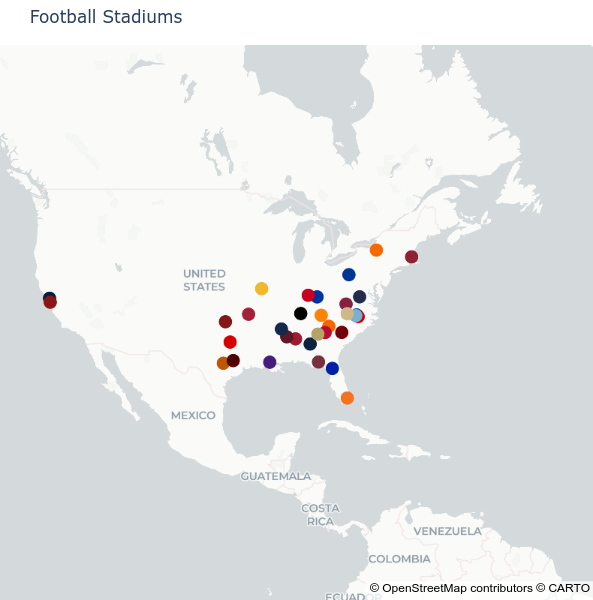

In [5]:
# map the 'stadiums'

import plotly.express as px

fig = px.scatter_map(
    stadiums,
    lat="latitude",
    lon="longitude",
    color="color",
    color_discrete_map="identity",
    hover_name="team",
    hover_data={
        "stadium": True,
        "city": True,
        "state": True,
        "capacity": ":,",
        "latitude": False,
        "longitude": False,
        "color": False,
    },
    center={"lat": stadiums["latitude"].mean(), "lon": stadiums["longitude"].mean()},
    zoom=np.log2(360 / max(np.ptp(stadiums["latitude"]), np.ptp(stadiums["longitude"]))) - 0.5,
    title="Football Stadiums",
)

fig.update_traces(marker={"size": 14})
fig.update_layout(
    map_style="carto-positron",
    height=600,
    margin={"r": 0, "t": 45, "l": 0, "b": 0},
)

fig.show()

With 16 SEC stadiums, there are $(16 - 1)! / 2 \approx 6.54 \times 10^{11}$ possible round-trip tours—far too many to brute-force in a lecture, yet small enough for a Mixed-Integer Linear Program (MILP) to find the provably optimal tour.

In practice, nobody uses MTZ for $n \ge 30$. Instead, solvers use the Dantzig–Fulkerson–Johnson (DFJ) formulation: solve the assignment problem without any subtour constraints first, check if the solution broke into disconnected loops (like a Texas/Oklahoma loop), add constraints forbidding only those specific loops, and re-solve. 


In [6]:
import highspy
import pulp

print(f"HiGHS version: {highspy.HIGHS_VERSION_MAJOR}.{highspy.HIGHS_VERSION_MINOR}.{highspy.HIGHS_VERSION_PATCH}")
print("Available PuLP solvers:", pulp.listSolvers(onlyAvailable=True))

HiGHS version: 1.16.0
Available PuLP solvers: ['GLPK_CMD', 'CPSAT', 'HiGHS']


In [7]:
%%time

import pulp
import networkx as nx
import highspy

teams = dist_matrix.index.tolist()
n = len(teams)
D = dist_matrix.to_numpy()

prob = pulp.LpProblem("TSP_DFJ", pulp.LpMinimize)
x = prob.add_variable_dicts(
    "x", [(i, j) for i in range(n) for j in range(n) if i != j], cat="Binary"
)

prob += pulp.lpSum(D[i, j] * x[(i, j)] for i in range(n) for j in range(n) if i != j)

for i in range(n):
    prob += pulp.lpSum(x[(i, j)] for j in range(n) if i != j) == 1
for j in range(n):
    prob += pulp.lpSum(x[(i, j)] for i in range(n) if i != j) == 1

solver = pulp.getSolver("HiGHS", msg=True, timeLimit=10, gapRel=0.01)

# Iteratively solve and add subtour elimination cuts until 1 single tour remains
while True:
    prob.solve(solver)
    
    # Build directed graph of active edges
    G = nx.DiGraph()
    G.add_edges_from((i, j) for (i, j), var in x.items() if pulp.value(var) > 0.5)
    
    components = list(nx.strongly_connected_components(G))
    if len(components) == 1:
        break  # Single valid tour found!
        
    # Forbid each disconnected subtour S: sum of edges inside S <= |S| - 1
    for S in components:
        if len(S) < n:
            prob += (
                pulp.lpSum(x[(i, j)] for i in S for j in S if i != j) <= len(S) - 1
            )

# Extract ordered tour starting at index 0
next_stop = {i: j for (i, j), var in x.items() if pulp.value(var) > 0.5}
tour = [0]
while len(tour) < n:
    tour.append(next_stop[tour[-1]])
tour.append(0)

print(f"Provably Optimal Tour Distance: {pulp.value(prob.objective):,.1f} miles")
print(" -> ".join(teams[i] for i in tour))

Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
MIP has 66 rows; 1056 cols; 2112 nonzeros; 1056 integer variables (1056 binary)
Coefficient ranges:
  Matrix  [1e+00, 1e+00]
  Cost    [9e+00, 3e+03]
  Bound   [1e+00, 1e+00]
  RHS     [1e+00, 1e+00]
Presolving model
66 rows, 1056 cols, 2112 nonzeros 0s
66 rows, 1056 cols, 2112 nonzeros 0s
Presolve reductions: rows 66(-0); columns 1056(-0); nonzeros 2112(-0) - Not reduced

Solving MIP model with:
   66 rows
   1056 cols (1056 binary, 0 integer, 0 implied int., 0 continuous, 0 domain fixed)
   2112 nonzeros
   Thread count: 12 available cores, 20 logical processors, using up to 12 workers across 12 threads.

Src: B => Branching; C => Central rounding; F => Feasibility pump; H => Heuristic;
     I => Shifting; J => Feasibility jump; L => Sub-MIP; P => Empty MIP; R => Randomized rounding;
     S => Solve LP; T => Evaluat

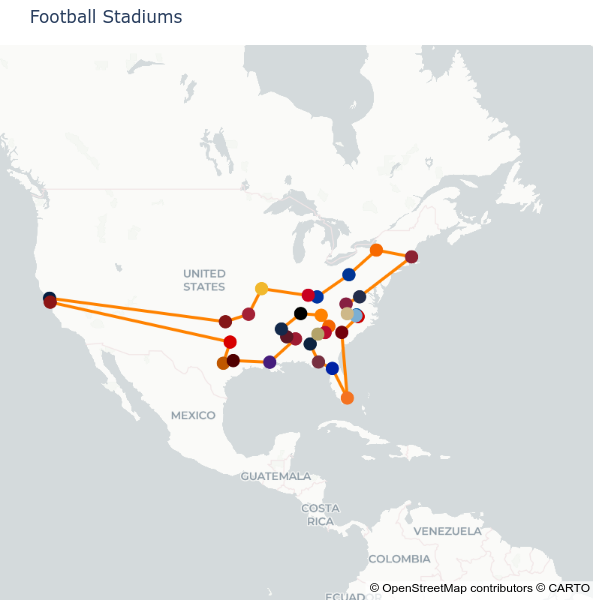

In [8]:
# add the tour to the map
tour_df = stadiums.iloc[tour].reset_index(drop=True)

line_fig = px.line_map(tour_df, lat="latitude", lon="longitude")
line_fig.update_traces(line={"width": 3, "color": "#FF8200"}, hoverinfo="skip")

fig.add_traces(list(line_fig.select_traces()))
fig.data = (fig.data[-1],) + fig.data[:-1]  # Keep markers drawn above the line

fig.show()

In [9]:
%%time
# get a quick heuristic solution

# Build weighted complete graph directly from your distance DataFrame
G = nx.from_pandas_adjacency(dist_matrix)

tour_names = nx.approximation.traveling_salesman_problem(G, cycle=True)

total_miles = sum(G[u][v]["weight"] for u, v in zip(tour_names[:-1], tour_names[1:]))
print(f"Christofides + 2-opt Distance: {total_miles:,.1f} miles")
print(tour_names)

Christofides + 2-opt Distance: 8,904.4 miles
['Alabama', 'Auburn', 'Miami', 'Florida', 'Florida State', 'Georgia Tech', 'Georgia', 'Clemson', 'Wake Forest', 'Virginia Tech', 'Virginia', 'Pittsburgh', 'Syracuse', 'Boston College', 'NC State', 'Duke', 'North Carolina', 'South Carolina', 'Tennessee', 'Kentucky', 'Louisville', 'Vanderbilt', 'Mississippi State', 'Ole Miss', 'Arkansas', 'Missouri', 'Oklahoma', 'California', 'Stanford', 'SMU', 'Texas A&M', 'Texas', 'LSU', 'Alabama']
CPU times: user 10.6 ms, sys: 0 ns, total: 10.6 ms
Wall time: 10.7 ms
